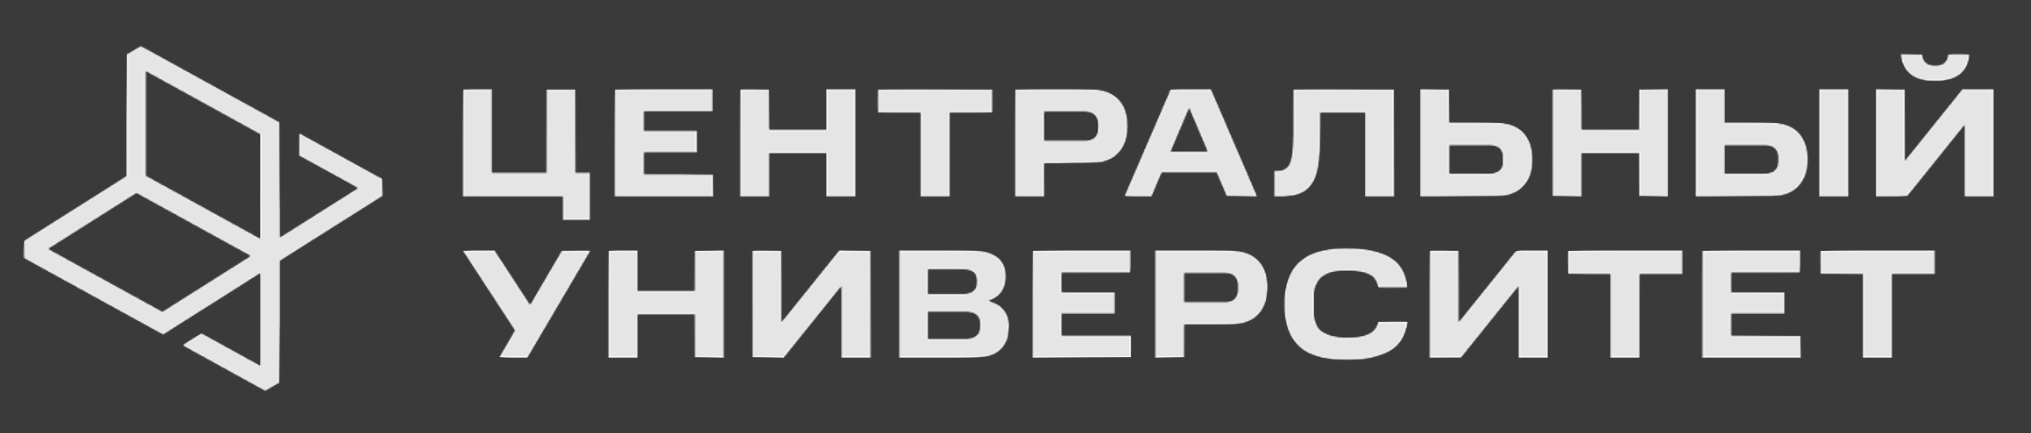


# Курс по прогнозированию временных рядов

# Неделя 10

## 10.11. Модель N-BeastX

In [ ]:
pip install neuralforecast

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from neuralforecast import NeuralForecast
from neuralforecast.models import NBEATSx
from neuralforecast.losses.pytorch import MQLoss

In [ ]:
# Для метрик
from sklearn.metrics import mean_absolute_error

In [ ]:
# 1. Генерация данных (как в исходном примере)
np.random.seed(42)
dates = pd.date_range('2020-01-01', '2023-12-31', freq='D')
df = pd.DataFrame({
    'ds': dates,
    'y': (np.sin(2 * np.pi * dates.dayofyear / 365) * 10 +
          np.random.normal(0, 1, len(dates)) +
          np.cos(2 * np.pi * dates.dayofweek / 7) * 5),
    'unique_id': 'series_1',
    'day_of_week': dates.dayofweek,
    'month': dates.month,
    'temperature': np.random.normal(20, 5, len(dates))
})

In [ ]:
df.head()

,ds,y,unique_id,day_of_week,month,temperature
0,2020-01-01,-0.443757,series_1,2,1,13.878509
1,2020-01-02,-4.298893,series_1,3,1,18.954884
2,2020-01-03,-3.340959,series_1,4,1,15.747398
3,2020-01-04,1.098449,series_1,5,1,17.097383
4,2020-01-05,3.742944,series_1,6,1,22.942892


In [ ]:
df.tail()

,ds,y,unique_id,day_of_week,month,temperature
1456,2023-12-27,-1.047287,series_1,2,12,23.343274
1457,2023-12-28,-4.639883,series_1,3,12,20.490338
1458,2023-12-29,-3.559308,series_1,4,12,26.479359
1459,2023-12-30,-0.611557,series_1,5,12,16.405838
1460,2023-12-31,2.978993,series_1,6,12,23.725027


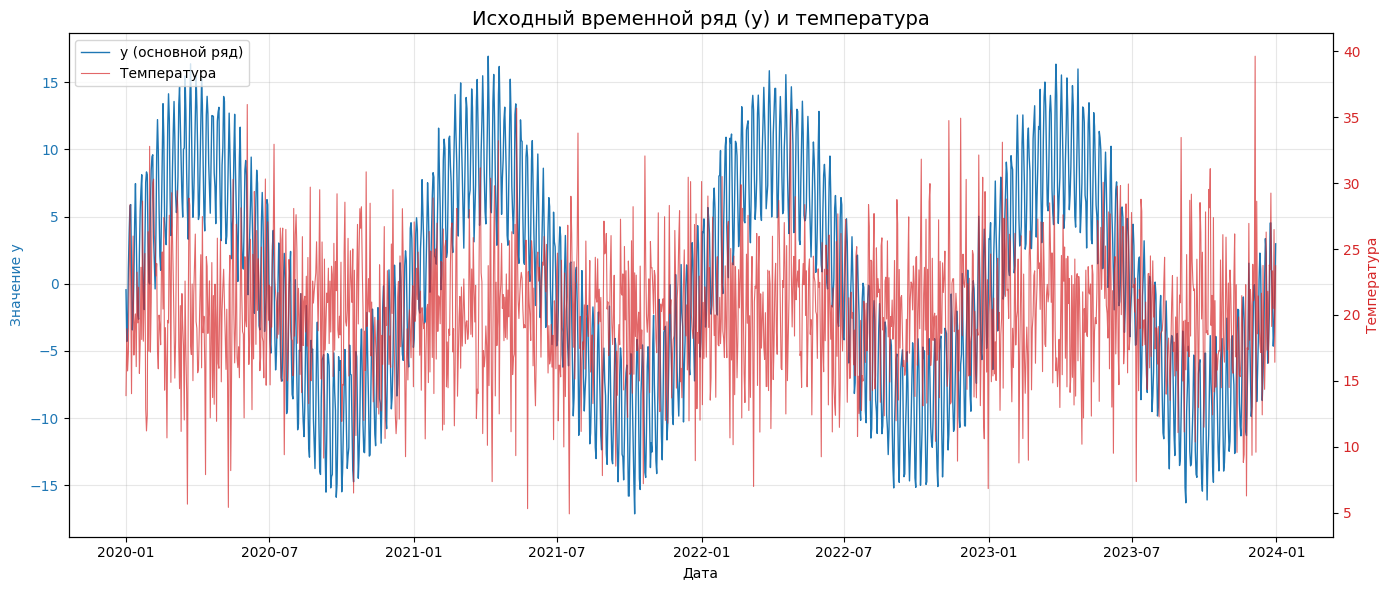

In [ ]:
# Визуализация исходного ряда и температуры
fig, ax1 = plt.subplots(figsize=(14, 6))

# Ось для основного ряда y
color = 'tab:blue'
ax1.set_xlabel('Дата')
ax1.set_ylabel('Значение y', color=color)
ax1.plot(df['ds'], df['y'], color=color, linewidth=1, label='y (основной ряд)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, alpha=0.3)

# Вторая ось — для температуры
ax2 = ax1.twinx()  # общая ось X
color = 'tab:red'
ax2.set_ylabel('Температура', color=color)
ax2.plot(df['ds'], df['temperature'], color=color, linewidth=0.8, alpha=0.7, label='Температура')
ax2.tick_params(axis='y', labelcolor=color)

# Заголовок
plt.title('Исходный временной ряд (y) и температура', fontsize=14)

# Добавим легенду (вручную, так как оси разные)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

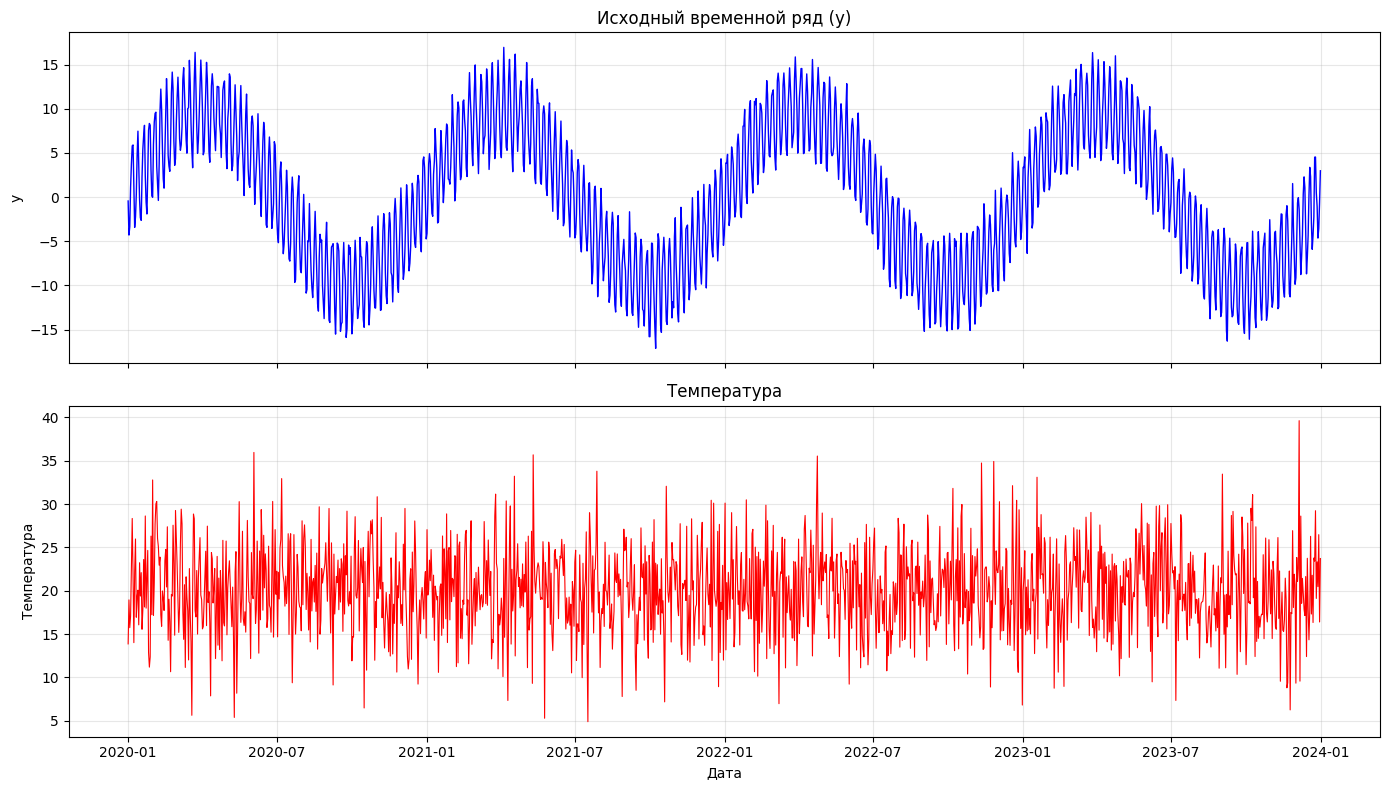

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Основной ряд y
ax1.plot(df['ds'], df['y'], color='blue', linewidth=1)
ax1.set_ylabel('y')
ax1.set_title('Исходный временной ряд (y)')
ax1.grid(True, alpha=0.3)

# Температура
ax2.plot(df['ds'], df['temperature'], color='red', linewidth=0.8)
ax2.set_ylabel('Температура')
ax2.set_xlabel('Дата')
ax2.set_title('Температура')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Разделение
train_df = df[df['ds'] < '2023-11-01'].copy()
test_df = df[df['ds'] >= '2023-11-01'].copy()

In [ ]:
# Горизонт прогноза
h = 30
freq = 'D'

# Берём только первые h дней теста (модель прогнозирует только h шагов)
test_subset = test_df.iloc[:h].copy()

In [ ]:
# 2. =============== МОДЕЛЬ С ЭКЗОГЕННЫМИ ПЕРЕМЕННЫМИ ===============
print("Обучение модели с экзогенными переменными...")

model_with_exog = NBEATSx(
    h=h,
    input_size=60,
    futr_exog_list=['day_of_week', 'month', 'temperature'],
    hist_exog_list=['temperature'],
    stack_types=['trend', 'seasonality', 'exogenous'],
    n_blocks=[1, 1, 1],
    mlp_units=[[64, 64], [64, 64], [64, 64]],
    loss=MQLoss(level=[50, 80, 90]),
    scaler_type='robust',
    max_steps=200,
    learning_rate=1e-3,
    random_seed=42
)

nf_with_exog = NeuralForecast(models=[model_with_exog], freq=freq)
nf_with_exog.fit(df=train_df, val_size=30)

futr_df_with_exog = test_subset[['ds', 'unique_id', 'day_of_week', 'month', 'temperature']].copy()
pred_with_exog = nf_with_exog.predict(futr_df=futr_df_with_exog).reset_index()


INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores


Обучение модели с экзогенными переменными...


┏━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name         ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss         │ MQLoss        │      7 │ train │     0 │
│ 1 │ padder_train │ ConstantPad1d │      0 │ train │     0 │
│ 2 │ scaler       │ TemporalNorm  │      0 │ train │     0 │
│ 3 │ blocks       │ ModuleList    │  150 K │ train │     0 │
└───┴──────────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 144 K                                                                                            
Non-trainable params: 5.5 K                                                                                        
Total params: 150 K                                                                                                
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 31                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=200` reached.


INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores


Output()

In [ ]:
# 3. =============== МОДЕЛЬ БЕЗ ЭКЗОГЕННЫХ ПЕРЕМЕННЫХ ===============
print("Обучение модели без экзогенных переменных...")

model_no_exog = NBEATSx(
    h=h,
    input_size=60,
    # НИКАКИХ futr_exog_list и hist_exog_list
    stack_types=['trend', 'seasonality'],
    n_blocks=[2, 2],  # можно немного усилить внутренние блоки
    mlp_units=[[64, 64], [64, 64]],
    loss=MQLoss(level=[50, 80, 90]),
    scaler_type='robust',
    max_steps=200,
    learning_rate=1e-3,
    random_seed=42
)

nf_no_exog = NeuralForecast(models=[model_no_exog], freq=freq)
nf_no_exog.fit(df=train_df[['ds', 'y', 'unique_id']], val_size=30)  # только необходимые столбцы

# Для модели без экзогенности futr_df не нужен (или пустой)
pred_no_exog = nf_no_exog.predict().reset_index()  # прогноз на следующие h дней после train

INFO:lightning_fabric.utilities.seed:Seed set to 42


Обучение модели без экзогенных переменных...


INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores


┏━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name         ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss         │ MQLoss        │      7 │ train │     0 │
│ 1 │ padder_train │ ConstantPad1d │      0 │ train │     0 │
│ 2 │ scaler       │ TemporalNorm  │      0 │ train │     0 │
│ 3 │ blocks       │ ModuleList    │  123 K │ train │     0 │
└───┴──────────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 112 K                                                                                            
Non-trainable params: 11.0 K                                                                                       
Total params: 123 K                                                                                                
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 36                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=200` reached.


INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores


Output()

In [ ]:
# 4. =============== ПОДГОТОВКА ДАННЫХ ДЛЯ МЕТРИК ===============
# Объединяем прогнозы с фактическими значениями по дате

# Для модели с экзогенными
merged_with = pd.merge(
    test_subset[['ds', 'y']],
    pred_with_exog[['ds', 'NBEATSx-median']],
    on='ds',
    how='inner'
)

# Для модели без экзогенных
merged_no = pd.merge(
    test_subset[['ds', 'y']],
    pred_no_exog[['ds', 'NBEATSx-median']],
    on='ds',
    how='inner'
)

In [ ]:
# Проверка
assert len(merged_with) == h, "Модель с экзогенными: не все дни совпали"
assert len(merged_no) == h, "Модель без экзогенных: не все дни совпали"

y_true = merged_with['y'].values  # или merged_no — одинаковые

y_pred_with = merged_with['NBEATSx-median'].values
y_pred_no = merged_no['NBEATSx-median'].values

In [ ]:
# 5. =============== ФУНКЦИЯ ДЛЯ sMAPE ===============
def smape(a, f):
    """
    Symmetric Mean Absolute Percentage Error
    """
    return 100 / len(a) * np.sum(2 * np.abs(f - a) / (np.abs(a) + np.abs(f)))

# 6. =============== ВЫЧИСЛЕНИЕ МЕТРИК ===============
mae_with = mean_absolute_error(y_true, y_pred_with)
smape_with = smape(y_true, y_pred_with)

mae_no = mean_absolute_error(y_true, y_pred_no)
smape_no = smape(y_true, y_pred_no)


In [ ]:
# 7. =============== ВЫВОД РЕЗУЛЬТАТОВ ===============
print("\n" + "="*50)
print("Сравнение моделей на тестовой выборке (30 дней)")
print("="*50)
print(f"{'Метрика':<15} {'С экзогенными':<15} {'Без экзогенных':<15}")
print("-"*50)
print(f"{'MAE':<15} {mae_with:<15.4f} {mae_no:<15.4f}")
print(f"{'sMAPE (%)':<15} {smape_with:<15.4f} {smape_no:<15.4f}")
print("="*50)


Сравнение моделей на тестовой выборке (30 дней)
Метрика         С экзогенными   Без экзогенных 
--------------------------------------------------
MAE             1.8154          0.8913         
sMAPE (%)       35.6693         23.5997        


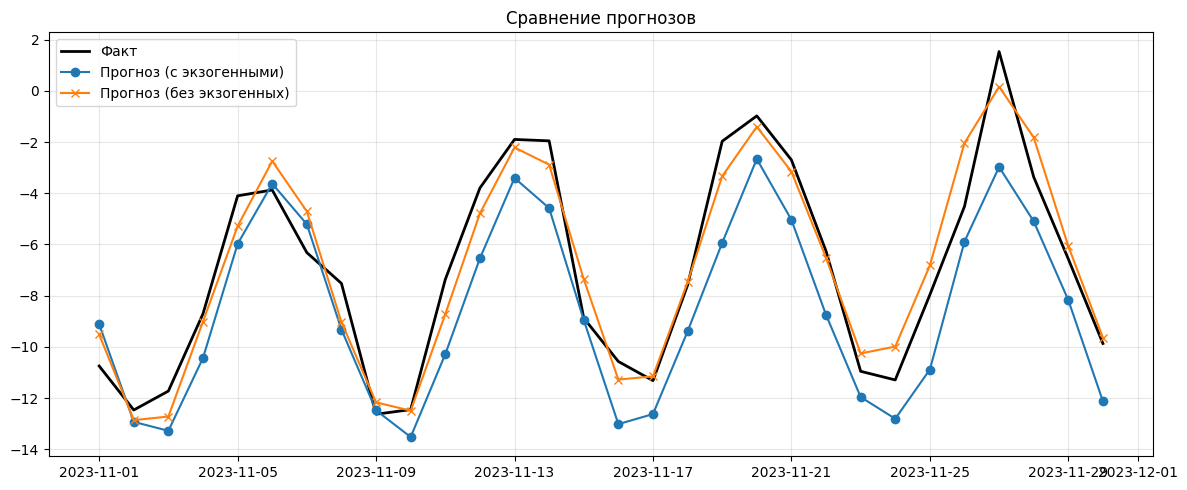

In [ ]:
# 8. Визуализация прогнозов
plt.figure(figsize=(12, 5))
plt.plot(test_subset['ds'], test_subset['y'], label='Факт', color='black', linewidth=2)
plt.plot(test_subset['ds'], y_pred_with, label='Прогноз (с экзогенными)', marker='o')
plt.plot(test_subset['ds'], y_pred_no, label='Прогноз (без экзогенных)', marker='x')
plt.title('Сравнение прогнозов')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Посмотрим на связь между `y` и `temperature`

Мы просто добавляли температуру как гауссовский шум и скорее всего она на `y` мало влияет.

In [ ]:
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import LinearRegression

In [ ]:
# 1. Глобальная корреляция
pearson_corr, p_pearson = pearsonr(df['y'], df['temperature'])
spearman_corr, p_spearman = spearmanr(df['y'], df['temperature'])

print("=== Глобальная связь между y и температурой ===")
print(f"Корреляция Пирсона: {pearson_corr:.4f} (p-value: {p_pearson:.2e})")
print(f"Корреляция Спирмена: {spearman_corr:.4f} (p-value: {p_spearman:.2e})")
print()

# Интерпретация
if abs(pearson_corr) < 0.1:
    strength = "очень слабая"
elif abs(pearson_corr) < 0.3:
    strength = "слабая"
elif abs(pearson_corr) < 0.5:
    strength = "умеренная"
else:
    strength = "сильная"

print(f"Интерпретация: линейная связь — {strength}")
print()

=== Глобальная связь между y и температурой ===
Корреляция Пирсона: 0.0133 (p-value: 6.11e-01)
Корреляция Спирмена: 0.0243 (p-value: 3.53e-01)

Интерпретация: линейная связь — очень слабая



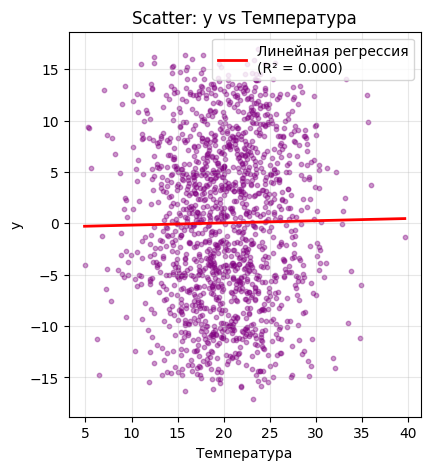

In [ ]:
# 2. Scatter plot
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.scatter(df['temperature'], df['y'], alpha=0.4, s=10, color='purple')
plt.xlabel('Температура')
plt.ylabel('y')
plt.title('Scatter: y vs Температура')
plt.grid(True, alpha=0.3)

# Линия линейной регрессии
X = df[['temperature']].values
y = df['y'].values
model = LinearRegression().fit(X, y)
y_pred_line = model.predict(np.linspace(df['temperature'].min(), df['temperature'].max(), 100).reshape(-1, 1))
plt.plot(np.linspace(df['temperature'].min(), df['temperature'].max(), 100), y_pred_line,
         color='red', linewidth=2, label=f'Линейная регрессия\n(R² = {model.score(X, y):.3f})')
plt.legend()


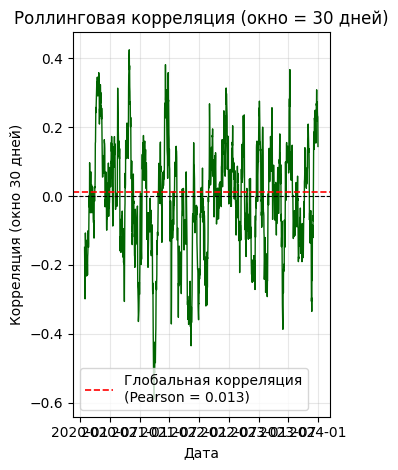

In [ ]:
# 3. Скользящая корреляция (например, окно 30 дней)
window = 30
df['rolling_corr'] = df['y'].rolling(window=window).corr(df['temperature'])

plt.subplot(1, 2, 2)
plt.plot(df['ds'], df['rolling_corr'], color='darkgreen', linewidth=1)
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.axhline(pearson_corr, color='red', linestyle='--', linewidth=1.2, label=f'Глобальная корреляция\n(Pearson = {pearson_corr:.3f})')
plt.xlabel('Дата')
plt.ylabel('Корреляция (окно 30 дней)')
plt.title(f'Скользящая корреляция (окно = {window} дней)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 4. Дополнительно: статистика по регрессии
coef = model.coef_[0]
intercept = model.intercept_
print("=== Линейная регрессия: y = a * temperature + b ===")
print(f"Коэффициент (a): {coef:.4f}")
print(f"Свободный член (b): {intercept:.4f}")
print(f"R²: {model.score(X, y):.4f}")
print(f"Интерпретация: при росте температуры на 1 градус, y в среднем {'растёт' if coef > 0 else 'падает'} на {abs(coef):.4f}")

=== Линейная регрессия: y = a * temperature + b ===
Коэффициент (a): 0.0215
Свободный член (b): -0.3930
R²: 0.0002
Интерпретация: при росте температуры на 1 градус, y в среднем растёт на 0.0215


## Сделаем температуру и `y` зависимыми

In [ ]:
# 1. Генерация данных (как в исходном примере)
np.random.seed(42)
dates = pd.date_range('2020-01-01', '2023-12-31', freq='D')
df = pd.DataFrame({
    'ds': dates,
    'y': (np.sin(2 * np.pi * dates.dayofyear / 365) * 10 +
          1.0 * df['temperature'] +
          np.cos(2 * np.pi * dates.dayofweek / 7) * 5),
    'unique_id': 'series_1',
    'day_of_week': dates.dayofweek,
    'month': dates.month,
    'temperature': np.random.normal(20, 5, len(dates))
})

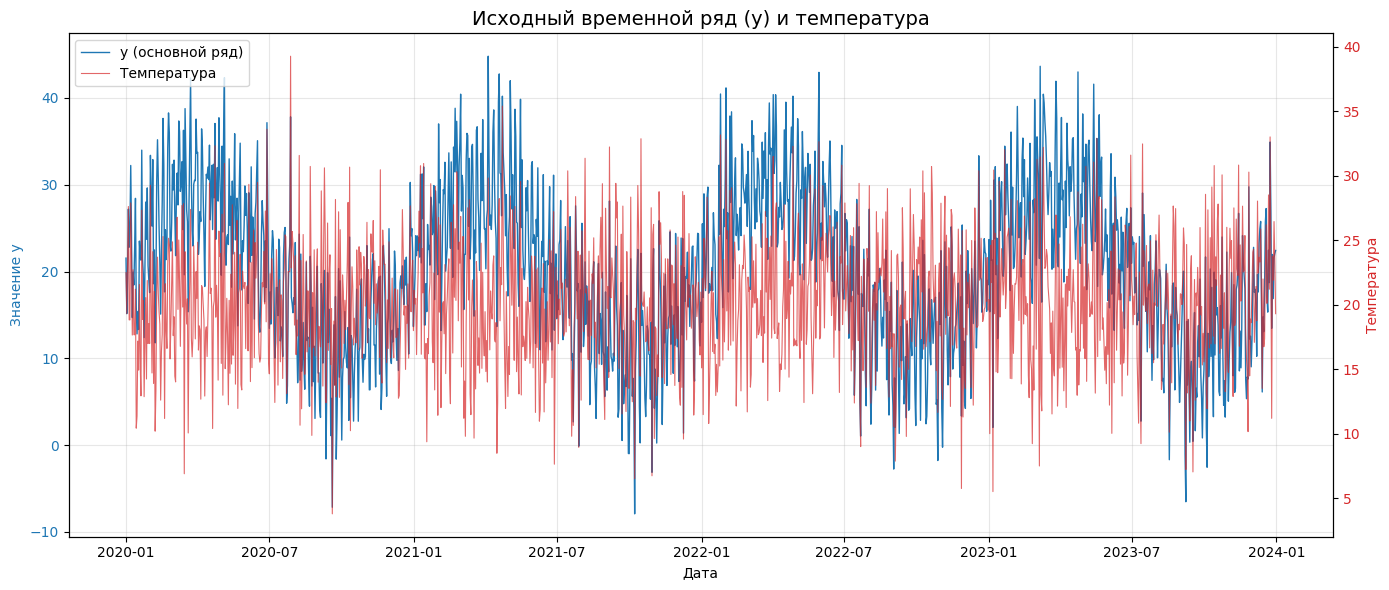

In [ ]:
# Визуализация исходного ряда и температуры
fig, ax1 = plt.subplots(figsize=(14, 6))

# Ось для основного ряда y
color = 'tab:blue'
ax1.set_xlabel('Дата')
ax1.set_ylabel('Значение y', color=color)
ax1.plot(df['ds'], df['y'], color=color, linewidth=1, label='y (основной ряд)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, alpha=0.3)

# Вторая ось — для температуры
ax2 = ax1.twinx()  # общая ось X
color = 'tab:red'
ax2.set_ylabel('Температура', color=color)
ax2.plot(df['ds'], df['temperature'], color=color, linewidth=0.8, alpha=0.7, label='Температура')
ax2.tick_params(axis='y', labelcolor=color)

# Заголовок
plt.title('Исходный временной ряд (y) и температура', fontsize=14)

# Добавим легенду (вручную, так как оси разные)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
# 1. Глобальная корреляция
pearson_corr, p_pearson = pearsonr(df['y'], df['temperature'])
spearman_corr, p_spearman = spearmanr(df['y'], df['temperature'])

print("=== Глобальная связь между y и температурой ===")
print(f"Корреляция Пирсона: {pearson_corr:.4f} (p-value: {p_pearson:.2e})")
print(f"Корреляция Спирмена: {spearman_corr:.4f} (p-value: {p_spearman:.2e})")
print()

# Интерпретация
if abs(pearson_corr) < 0.1:
    strength = "очень слабая"
elif abs(pearson_corr) < 0.3:
    strength = "слабая"
elif abs(pearson_corr) < 0.5:
    strength = "умеренная"
else:
    strength = "сильная"

print(f"Интерпретация: линейная связь — {strength}")
print()

=== Глобальная связь между y и температурой ===
Корреляция Пирсона: 0.5237 (p-value: 1.10e-103)
Корреляция Спирмена: 0.4747 (p-value: 5.78e-83)

Интерпретация: линейная связь — сильная



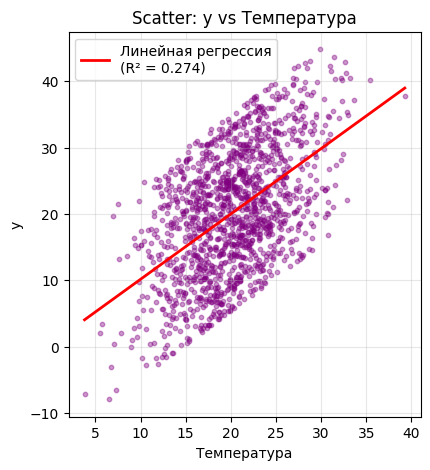

In [ ]:
# 2. Scatter plot
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.scatter(df['temperature'], df['y'], alpha=0.4, s=10, color='purple')
plt.xlabel('Температура')
plt.ylabel('y')
plt.title('Scatter: y vs Температура')
plt.grid(True, alpha=0.3)

# Линия линейной регрессии
X = df[['temperature']].values
y = df['y'].values
model = LinearRegression().fit(X, y)
y_pred_line = model.predict(np.linspace(df['temperature'].min(), df['temperature'].max(), 100).reshape(-1, 1))
plt.plot(np.linspace(df['temperature'].min(), df['temperature'].max(), 100), y_pred_line,
         color='red', linewidth=2, label=f'Линейная регрессия\n(R² = {model.score(X, y):.3f})')
plt.legend()


### Теперь видно, что `y` и температура связаны друг с другом.

Перестрои наши модели.

In [ ]:
# Разделение
train_df = df[df['ds'] < '2023-11-01'].copy()
test_df = df[df['ds'] >= '2023-11-01'].copy()

In [ ]:
# Горизонт прогноза
h = 30
freq = 'D'

# Берём только первые h дней теста (модель прогнозирует только h шагов)
test_subset = test_df.iloc[:h].copy()

In [ ]:
# 2. =============== МОДЕЛЬ С ЭКЗОГЕННЫМИ ПЕРЕМЕННЫМИ ===============
print("Обучение модели с экзогенными переменными...")

model_with_exog = NBEATSx(
    h=h,
    input_size=60,
    futr_exog_list=['day_of_week', 'month', 'temperature'],
    hist_exog_list=['temperature'],
    stack_types=['trend', 'seasonality', 'exogenous'],
    n_blocks=[1, 1, 1],
    mlp_units=[[64, 64], [64, 64], [64, 64]],
    loss=MQLoss(level=[50, 80, 90]),
    scaler_type='robust',
    max_steps=200,
    learning_rate=1e-3,
    random_seed=42
)

nf_with_exog = NeuralForecast(models=[model_with_exog], freq=freq)
nf_with_exog.fit(df=train_df, val_size=30)

futr_df_with_exog = test_subset[['ds', 'unique_id', 'day_of_week', 'month', 'temperature']].copy()
pred_with_exog = nf_with_exog.predict(futr_df=futr_df_with_exog).reset_index()

INFO:lightning_fabric.utilities.seed:Seed set to 42


Обучение модели с экзогенными переменными...


INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores


┏━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name         ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss         │ MQLoss        │      7 │ train │     0 │
│ 1 │ padder_train │ ConstantPad1d │      0 │ train │     0 │
│ 2 │ scaler       │ TemporalNorm  │      0 │ train │     0 │
│ 3 │ blocks       │ ModuleList    │  150 K │ train │     0 │
└───┴──────────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 144 K                                                                                            
Non-trainable params: 5.5 K                                                                                        
Total params: 150 K                                                                                                
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 31                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=200` reached.


INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores


Output()

In [ ]:
# 3. =============== МОДЕЛЬ БЕЗ ЭКЗОГЕННЫХ ПЕРЕМЕННЫХ ===============
print("Обучение модели без экзогенных переменных...")

model_no_exog = NBEATSx(
    h=h,
    input_size=60,
    # НИКАКИХ futr_exog_list и hist_exog_list
    stack_types=['trend', 'seasonality'],
    n_blocks=[2, 2],  # можно немного усилить внутренние блоки
    mlp_units=[[64, 64], [64, 64]],
    loss=MQLoss(level=[50, 80, 90]),
    scaler_type='robust',
    max_steps=200,
    learning_rate=1e-3,
    random_seed=42
)

nf_no_exog = NeuralForecast(models=[model_no_exog], freq=freq)
nf_no_exog.fit(df=train_df[['ds', 'y', 'unique_id']], val_size=30)  # только необходимые столбцы

# Для модели без экзогенности futr_df не нужен (или пустой)
pred_no_exog = nf_no_exog.predict().reset_index()  # прогноз на следующие h дней после train

INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores


Обучение модели без экзогенных переменных...


┏━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name         ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss         │ MQLoss        │      7 │ train │     0 │
│ 1 │ padder_train │ ConstantPad1d │      0 │ train │     0 │
│ 2 │ scaler       │ TemporalNorm  │      0 │ train │     0 │
│ 3 │ blocks       │ ModuleList    │  123 K │ train │     0 │
└───┴──────────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 112 K                                                                                            
Non-trainable params: 11.0 K                                                                                       
Total params: 123 K                                                                                                
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 36                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=200` reached.


INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores


Output()

In [ ]:
# 4. =============== ПОДГОТОВКА ДАННЫХ ДЛЯ МЕТРИК ===============
# Объединяем прогнозы с фактическими значениями по дате

# Для модели с экзогенными
merged_with = pd.merge(
    test_subset[['ds', 'y']],
    pred_with_exog[['ds', 'NBEATSx-median']],
    on='ds',
    how='inner'
)

# Для модели без экзогенных
merged_no = pd.merge(
    test_subset[['ds', 'y']],
    pred_no_exog[['ds', 'NBEATSx-median']],
    on='ds',
    how='inner'
)

In [ ]:
# Проверка
assert len(merged_with) == h, "Модель с экзогенными: не все дни совпали"
assert len(merged_no) == h, "Модель без экзогенных: не все дни совпали"

y_true = merged_with['y'].values  # или merged_no — одинаковые

y_pred_with = merged_with['NBEATSx-median'].values
y_pred_no = merged_no['NBEATSx-median'].values

In [ ]:
# 6. =============== ВЫЧИСЛЕНИЕ МЕТРИК ===============
mae_with = mean_absolute_error(y_true, y_pred_with)
smape_with = smape(y_true, y_pred_with)

mae_no = mean_absolute_error(y_true, y_pred_no)
smape_no = smape(y_true, y_pred_no)


In [ ]:
# 7. =============== ВЫВОД РЕЗУЛЬТАТОВ ===============
print("\n" + "="*50)
print("Сравнение моделей на тестовой выборке (30 дней)")
print("="*50)
print(f"{'Метрика':<15} {'С экзогенными':<15} {'Без экзогенных':<15}")
print("-"*50)
print(f"{'MAE':<15} {mae_with:<15.4f} {mae_no:<15.4f}")
print(f"{'sMAPE (%)':<15} {smape_with:<15.4f} {smape_no:<15.4f}")
print("="*50)


Сравнение моделей на тестовой выборке (30 дней)
Метрика         С экзогенными   Без экзогенных 
--------------------------------------------------
MAE             1.5157          4.4994         
sMAPE (%)       14.5301         34.0709        


Совсем другое дело

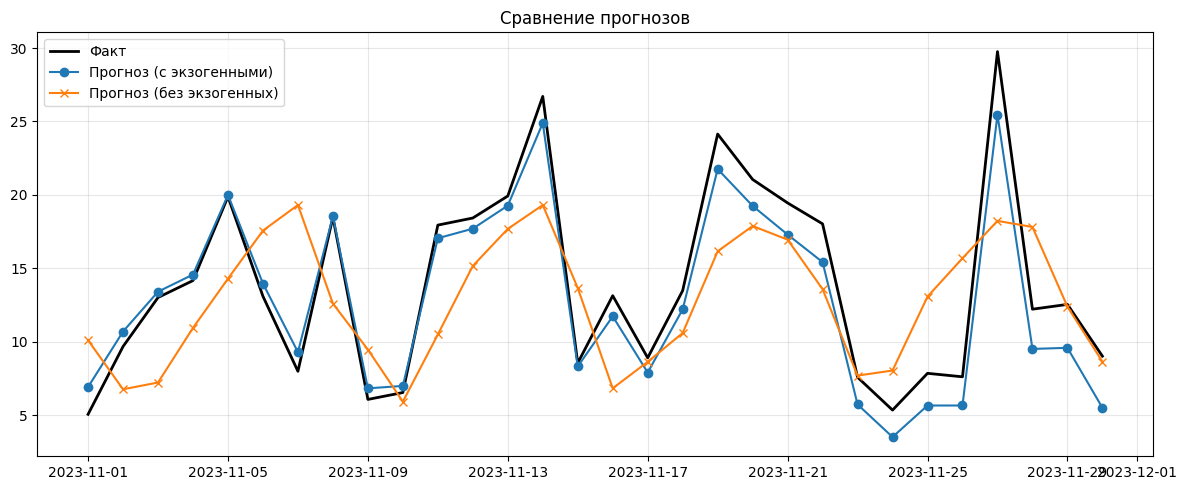

In [ ]:
# 8. Визуализация прогнозов
plt.figure(figsize=(12, 5))
plt.plot(test_subset['ds'], test_subset['y'], label='Факт', color='black', linewidth=2)
plt.plot(test_subset['ds'], y_pred_with, label='Прогноз (с экзогенными)', marker='o')
plt.plot(test_subset['ds'], y_pred_no, label='Прогноз (без экзогенных)', marker='x')
plt.title('Сравнение прогнозов')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()